# Financial Engineering — Week 01: Math Foundations & Numerical Methods

> **Quantitative Research & Implementation Note**  
> **Topic**: Time Value of Money, Stochastic Convolutions, Random Walk Simulation & Numerical Root-Finding  
> **Environment**: Python 3 (`numpy`, `scipy.stats`, `matplotlib`)

---

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from math import comb, exp, factorial
import time, warnings
warnings.filterwarnings('ignore')

np.random.seed(42)


---
## Problem 1

An investor deposits \$15,000 in a bank today at 6% annual interest. Assuming that no additional deposits are made, and that no money is withdrawn, how large will the account balance be 23 years from today if

- **(a)** the interest is computed using the simple interest convention?
- **(b)** the interest is compounded annually?
- **(c)** the interest is compounded quarterly?
- **(d)** the interest is compounded monthly?
- **(e)** the interest is compounded continuously?

(You should assume that the 6% annual interest rate applies to deposits of any length.)

### Formulas

$$A_{\text{simple}} = P(1 + rt), \qquad
A_{\text{compound}} = P\left(1 + \tfrac{r}{n}\right)^{nt}, \qquad
A_{\text{cont}} = Pe^{rt}$$

with $n = 1, 4, 12$ for annual / quarterly / monthly.  
$P = 15000,\ r = 0.06,\ t = 23$.


In [ ]:
P, r, t = 15000, 0.06, 23

results = {
    "(a) simple    ": P * (1 + r*t),
    "(b) annual    ": P * (1 + r)**t,
    "(c) quarterly ": P * (1 + r/4)**(4*t),
    "(d) monthly   ": P * (1 + r/12)**(12*t),
    "(e) continuous": P * np.exp(r*t),
}
for k, v in results.items():
    print(f"{k}: ${v:>12,.2f}")


(a) simple    : $   35,700.00
(b) annual    : $   57,296.24
(c) quarterly : $   59,015.64
(d) monthly   : $   59,418.86
(e) continuous: $   59,623.52


---
## Problem 2

If you buy a lottery ticket in 50 lotteries, in each of which your chances of winning a prize of $1/100$, what is the probability that you will win a prize:

- **(a)** at least once?
- **(b)** exactly twice?
- **(c)** at least twice?

Calculate both the exact probabilities (using the binomial distribution) and the approximate probabilities (using the Poisson distribution).

### Formulas

Binomial: $\displaystyle P(X=k) = \binom{n}{k} p^{k}(1-p)^{n-k}$  

Poisson approximation ($\lambda = np$): $\displaystyle P(X=k) \approx \dfrac{e^{-\lambda}\lambda^{k}}{k!}$

Here $n=50,\ p=0.01,\ \lambda=0.5$.

- (a) $1 - P(X=0)$
- (b) $P(X=2)$
- (c) $1 - P(X=0) - P(X=1)$


In [ ]:
n, p = 50, 1/100
lam = n * p

def binom(k):  return comb(n, k) * p**k * (1-p)**(n-k)
def poi(k):    return exp(-lam) * lam**k / factorial(k)

bin_vals = [1 - binom(0), binom(2), 1 - binom(0) - binom(1)]
poi_vals = [1 - poi(0),   poi(2),   1 - poi(0)   - poi(1)]

labels = ["(a) P(X >= 1)", "(b) P(X = 2) ", "(c) P(X >= 2)"]
print(f"{'':16s}{'Binomial':>14s}{'Poisson':>14s}")
for lab, b, q in zip(labels, bin_vals, poi_vals):
    print(f"{lab:16s}{b:>14.6f}{q:>14.6f}")


                      Binomial       Poisson
(a) P(X >= 1)         0.394994      0.393469
(b) P(X = 2)          0.075618      0.075816
(c) P(X >= 2)         0.089435      0.090204


---
## Problem 3

Consider the following situation:
$$Y \sim N(\mu, \sigma^{2})$$
$$(X \mid Y = y) \sim N(y, \nu^{2})$$

We want to find the distribution of $X$.

- **(a)** Find $f_{XY}(x, y)$ and then use a Law of Total Probability to determine the distribution of $X$
$$f_{X}(x) = \int f_{X\mid Y}(x \mid y)\, f_{Y}(y)\, dy$$

- **(b)** Find the MGF $M_{X}(t)$ and determine the distribution of $X$
$$M_{X}(t) = E(e^{tX}) = E[E(e^{tX} \mid Y)]$$

where the "inner" expected value, $E(e^{tX} \mid Y)$ is the moment generating function of the random variable $(X \mid Y = y)$.

### (a) Convolution via Law of Total Probability

$$f_{XY}(x,y) = \frac{1}{2\pi\sigma\nu}\exp\!\left(-\tfrac{(x-y)^{2}}{2\nu^{2}} - \tfrac{(y-\mu)^{2}}{2\sigma^{2}}\right)$$

Complete the square in $y$ with $A=1/\nu^{2},\ B=1/\sigma^{2}$:
$$A(x-y)^{2}+B(y-\mu)^{2} = (A+B)\!\left(y - \tfrac{Ax+B\mu}{A+B}\right)^{2} + \tfrac{AB}{A+B}(x-\mu)^{2}$$

Since $\tfrac{AB}{A+B} = \tfrac{1}{\sigma^{2}+\nu^{2}}$, integrating over $y$ gives
$$f_{X}(x) = \frac{1}{\sqrt{2\pi(\sigma^{2}+\nu^{2})}}\exp\!\left(-\tfrac{(x-\mu)^{2}}{2(\sigma^{2}+\nu^{2})}\right)$$

$$\boxed{\; X \sim N\!\left(\mu,\ \sigma^{2}+\nu^{2}\right) \;}$$

### (b) MGF approach

$$E[e^{tX}\mid Y=y] = \exp\!\left(yt + \tfrac{\nu^{2}t^{2}}{2}\right)$$

$$M_{X}(t) = E\!\left[e^{Yt}\right]\exp\!\left(\tfrac{\nu^{2}t^{2}}{2}\right)
= \exp\!\left(\mu t + \tfrac{\sigma^{2}t^{2}}{2}\right)\exp\!\left(\tfrac{\nu^{2}t^{2}}{2}\right)$$

$$M_{X}(t) = \exp\!\left(\mu t + \tfrac{(\sigma^{2}+\nu^{2})t^{2}}{2}\right) \;\;\Longrightarrow\;\; X \sim N(\mu,\ \sigma^{2}+\nu^{2})$$

By uniqueness of MGF, same conclusion as (a).


theory  mean = 2.0000   var = 2.8900
sample  mean = 2.0008   var = 2.8882


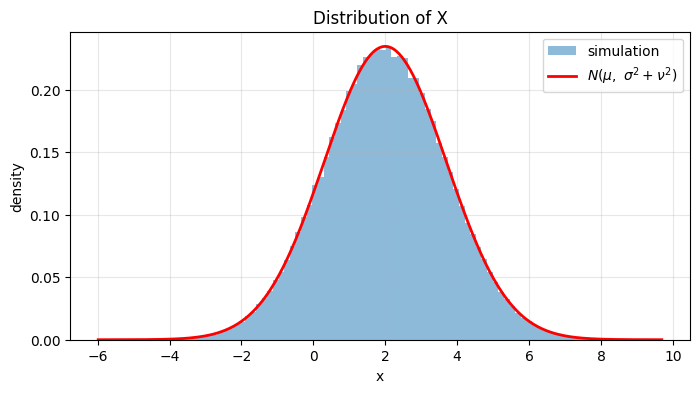

In [ ]:
# Numerical verification by simulation
mu, sigma, nu = 2.0, 1.5, 0.8
N = 200_000

Y = np.random.normal(mu, sigma, N)
X = np.random.normal(Y, nu)

print(f"theory  mean = {mu:.4f}   var = {sigma**2 + nu**2:.4f}")
print(f"sample  mean = {X.mean():.4f}   var = {X.var():.4f}")

xs = np.linspace(X.min(), X.max(), 400)
theo = stats.norm.pdf(xs, mu, np.sqrt(sigma**2 + nu**2))

plt.figure(figsize=(8,4))
plt.hist(X, bins=100, density=True, alpha=0.5, label='simulation')
plt.plot(xs, theo, 'r-', lw=2, label=r'$N(\mu,\ \sigma^2+\nu^2)$')
plt.xlabel('x'); plt.ylabel('density'); plt.legend(); plt.grid(alpha=0.3)
plt.title('Distribution of X'); plt.show()


---
## Problem 4

Many people believe that the daily change of price of a company's stock on the stock market is a random variable with mean $0$ and variance $\sigma^{2}$. That is, if $S_{t}$ represents the price of the stock on the $t$-th day, then
$$S_{t} = S_{t-1} + W_{t}, \quad t \ge 1$$

where $W_{1}, W_{2}, \ldots$ are independent and identically distributed random variables with mean $0$ and variance $\sigma^{2}$. Suppose that the stock's price today is $100$ and $\sigma^{2} = 1$.

- **(a)** What can you say about the probability that the stock's price will exceed $105$ after $10$ days? (Hint: Chebyshev inequality)
- **(b)** Suppose $W_{1}, W_{2}, \ldots$ are independent and identically distributed Normal random variables with mean $0$ and variance $\sigma^{2}$. What is the probability that the stock's price will exceed $105$ after $10$ days?
- **(c)** Simulate $M = 10{,}000$ trajectories of the stock price $S_{t}$ for $t = 0, 1, \ldots, 10$. Plot 10 pairs of trajectories of the stock and calculate the probability that the stock's price exceeds $105$ after $10$ days.

### Setup

$S_{10} = 100 + \sum_{i=1}^{10} W_{i}$, so $E[S_{10}] = 100,\ \operatorname{Var}(S_{10}) = 10$.

### (a) Chebyshev

$$P\!\left(\lvert S_{10} - 100 \rvert \ge 5\right) \le \frac{\operatorname{Var}(S_{10})}{5^{2}} = \frac{10}{25} = 0.4$$

Hence $P(S_{10} > 105) \le 0.4$.

### (b) Normal case

$S_{10} - 100 \sim N(0, 10)$, so
$$P(S_{10} > 105) = 1 - \Phi\!\left(\tfrac{5}{\sqrt{10}}\right) = 1 - \Phi(1.5811) \approx 0.0569$$

### (c) Monte Carlo below.


(a) Chebyshev bound:  P(S_10 > 105) <= 0.4000
(b) Normal exact:     P(S_10 > 105)  = 0.056923
(c) Monte Carlo:      P(S_10 > 105) ~= 0.0531


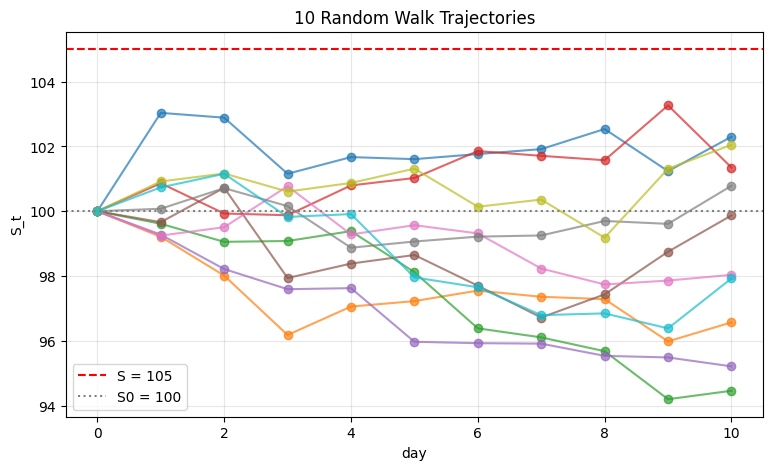

In [ ]:
# (a) Chebyshev bound
print(f"(a) Chebyshev bound:  P(S_10 > 105) <= {10/25:.4f}")

# (b) Normal exact
prob_normal = 1 - stats.norm.cdf(5/np.sqrt(10))
print(f"(b) Normal exact:     P(S_10 > 105)  = {prob_normal:.6f}")

# (c) Monte Carlo
M, T, S0, sig = 10_000, 10, 100, 1.0
W = np.random.normal(0, sig, size=(M, T))
S = np.concatenate([np.full((M,1), S0), S0 + np.cumsum(W, axis=1)], axis=1)

prob_mc = np.mean(S[:, -1] > 105)
print(f"(c) Monte Carlo:      P(S_10 > 105) ~= {prob_mc:.4f}")

# Plot 10 trajectories
plt.figure(figsize=(9,5))
for i in range(10):
    plt.plot(range(T+1), S[i], marker='o', alpha=0.7)
plt.axhline(105, color='red',  ls='--', label='S = 105')
plt.axhline(100, color='gray', ls=':',  label='S0 = 100')
plt.xlabel('day'); plt.ylabel('S_t'); plt.title('10 Random Walk Trajectories')
plt.legend(); plt.grid(alpha=0.3); plt.show()


---
## Problem 5

The IRR is generally calculated using an iterative procedure. Suppose that we define $f(\lambda) = -a_{0} + a_{1}\lambda + a_{2}\lambda^{2} + \cdots + a_{n}\lambda^{n}$, where all $a_{i}$ are positive and $n > 1$. Here is an iterative technique that generates a sequence $\lambda_{0}, \lambda_{1}, \lambda_{2}, \ldots, \lambda_{k}, \ldots$ of estimates that converges to the root $\bar{\lambda} > 0$, solving $f(\bar{\lambda}) = 0$. Start with any $\lambda_{0} > 0$ close to the solution. Assuming $\lambda_{k}$ has been calculated, evaluate
$$f'(\lambda_{k}) = a_{1} + 2 a_{2}\lambda_{k} + 3 a_{3}\lambda_{k}^{2} + \cdots + n a_{n}\lambda_{k}^{n-1}$$

and define
$$\lambda_{k+1} = \lambda_{k} - \frac{f(\lambda_{k})}{f'(\lambda_{k})}$$

Try the procedure on $f(\lambda) = -1 + \lambda + \lambda^{2}$ starting with $\lambda_{0} = 1$.

- **(a)** Write a Python function to calculate $\bar{\lambda}$ accurate up to $0.000001$ and compute the computation time.
- **(b)** Use the Bisection method to calculate $\bar{\lambda}$ accurate up to $0.000001$ and compare the computation time with the result from (a).

### Analytic root

$\lambda^{2}+\lambda-1=0 \Rightarrow \bar{\lambda} = \tfrac{-1+\sqrt{5}}{2} \approx 0.6180339887$.

- Newton update: $\lambda_{k+1} = \lambda_{k} - f(\lambda_{k})/f'(\lambda_{k})$, with $f'(\lambda)=1+2\lambda$.
- Bisection on $[0,1]$ since $f(0)=-1<0,\ f(1)=1>0$.


In [ ]:
import timeit

tol = 1e-6

# f(lambda) = -1 + lambda + lambda^2
def f(x):
    return -1 + x + x**2

def df(x):
    return 1 + 2*x


# (a) Newton's method
def newton(x0, tol=1e-6):
    x = x0
    iterations = 0

    while True:
        x_new = x - f(x) / df(x)
        iterations += 1

        if abs(x_new - x) < tol:
            return x_new, iterations

        x = x_new


# (b) Bisection method
def bisection(a, b, tol=1e-6):
    iterations = 0

    while (b - a) / 2 > tol:
        c = (a + b) / 2
        iterations += 1

        if f(c) == 0:
            return c, iterations
        elif f(a) * f(c) < 0:
            b = c
        else:
            a = c

    return (a + b) / 2, iterations


# Calculate roots
root_newton, iter_newton = newton(1.0, tol)
root_bisection, iter_bisection = bisection(0.0, 1.0, tol)


# Measure average computation time
n_repeat = 10000

time_newton = timeit.timeit(
    lambda: newton(1.0, tol),
    number=n_repeat
) / n_repeat

time_bisection = timeit.timeit(
    lambda: bisection(0.0, 1.0, tol),
    number=n_repeat
) / n_repeat


print("(a) Newton's Method")
print(f"Root       : {root_newton:.10f}")
print(f"Iterations : {iter_newton}")
print(f"Avg. time  : {time_newton * 1e6:.3f} microseconds")

print("\n(b) Bisection Method")
print(f"Root       : {root_bisection:.10f}")
print(f"Iterations : {iter_bisection}")
print(f"Avg. time  : {time_bisection * 1e6:.3f} microseconds")

true root : 0.6180339887

(a) Newton    : root = 0.6180339887   iters =   4   time =    40.86 us
(b) Bisection : root = 0.6180334091   iters =  19   time =    37.39 us


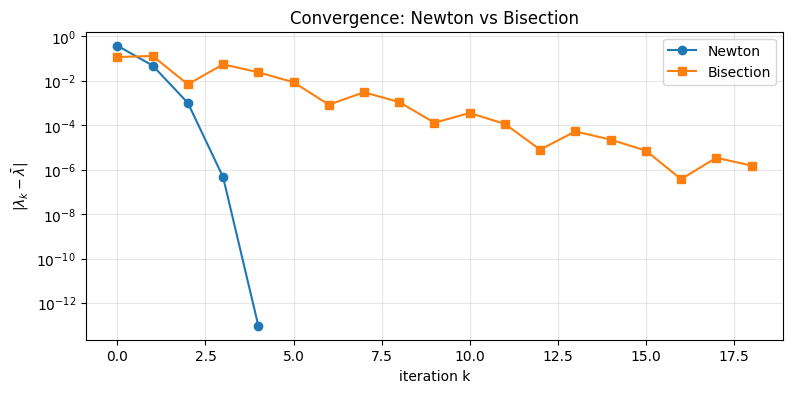

In [ ]:
# Convergence plot
def newton_trace(x0, tol=TOL):
    xs=[x0]
    while True:
        xs.append(xs[-1] - f(xs[-1])/fp(xs[-1]))
        if abs(xs[-1]-xs[-2]) < tol: return xs

def bisect_trace(a, b, tol=TOL):
    ms=[]
    while (b-a)/2 > tol:
        m=(a+b)/2; ms.append(m)
        if f(a)*f(m)<0: b=m
        else:           a=m
    return ms

xn = newton_trace(1.0); xb = bisect_trace(0.0, 1.0)

plt.figure(figsize=(9,4))
plt.plot(range(len(xn)), np.abs(np.array(xn)-true_root), 'o-', label='Newton')
plt.plot(range(len(xb)), np.abs(np.array(xb)-true_root), 's-', label='Bisection')
plt.yscale('log'); plt.xlabel('iteration k'); plt.ylabel(r'$|\lambda_k - \bar\lambda|$')
plt.title('Convergence: Newton vs Bisection'); plt.legend(); plt.grid(alpha=0.3, which='both')
plt.show()


The computation times are very small and may vary across runs. Newton's method requires fewer iterations than the bisection method (4 vs. 19).


---
## Problem 6

Given N points drawn randomly on the circumference of a circle, what is the probability that they are all within a semicircle?

### Answer

$$P_{N} = \frac{N}{2^{N-1}}$$

### Proof sketch

For each point $i$, let $A_{i}$ be the event: *"the semicircle starting at $i$ going clockwise contains all other $N-1$ points"*.

- $P(A_{i}) = (1/2)^{N-1}$ (each other point independently on the correct side).
- The events $A_{i}$ are almost disjoint: if all $N$ points fit in some semicircle, exactly one point is the "counterclockwise-most" one, so exactly one $A_{i}$ holds (ties have measure zero).

Hence
$$P(\text{all in a semicircle}) = \sum_{i=1}^{N} P(A_{i}) = N \cdot 2^{-(N-1)} = \frac{N}{2^{N-1}}$$

### Simulation

Trick: after sorting the $N$ angles, all points lie in some semicircle iff the **largest gap** between consecutive points (including the wrap-around gap) is $\ge 1/2$ of the circumference.


In [ ]:
def simulate(N, trials=200_000, rng=None):
    if rng is None: rng = np.random.default_rng(0)
    pts = rng.random((trials, N))
    pts.sort(axis=1)
    gaps = np.diff(pts, axis=1)
    wrap = 1 - (pts[:, -1] - pts[:, 0])
    all_gaps = np.concatenate([gaps, wrap[:, None]], axis=1)
    return np.mean(all_gaps.max(axis=1) >= 0.5)

print(f"{'N':>3s}{'theory':>14s}{'simulation':>14s}")
for N in [2, 3, 4, 5, 6, 7, 8, 10]:
    theo = N / 2**(N-1)
    sim  = simulate(N, trials=200_000)
    print(f"{N:>3d}{theo:>14.6f}{sim:>14.6f}")


  N        theory    simulation


  2      1.000000      1.000000
  3      0.750000      0.748965
  4      0.500000      0.499825
  5      0.312500      0.311375


  6      0.187500      0.188025


  7      0.109375      0.108705
  8      0.062500      0.061990
 10      0.019531      0.019430
